### Imports

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

from mlxtend.preprocessing import TransactionEncoder

from mlxtend.frequent_patterns import apriori

from mlxtend.frequent_patterns import association_rules

## Prepare Transactions

In [2]:
transactions =  pd.read_csv("../data/processed/supplier_transactions.csv")

transaction_list = transactions.values.tolist()

te = TransactionEncoder()

transaction_list = [
    [item for item in row if pd.notna(item)]
    for row in transactions.values.tolist()
]

te_array = te.fit(transaction_list).transform(transaction_list)

basket = pd.DataFrame(
    te_array,
    columns=te.columns_
)

basket.head()

,Fast_Delivery,Low_Defects,Low_Quality,Low_Reliability,Moderate_Delivery,Slow_Delivery,Supplier_Not_Selected,Supplier_Selected
0,False,True,True,True,False,True,False,True
1,True,True,True,True,False,False,True,False
2,True,True,True,True,False,False,True,False
3,False,True,True,True,False,True,False,True
4,False,True,True,True,False,True,True,False


## Frequent Itemsets

In [3]:
frequent_itemsets = apriori(
    basket,
    min_support=0.05,
    use_colnames=True
)

frequent_itemsets.sort_values(
    by='support',
    ascending=False
).head(20)

,support,itemsets
2,1.000000,frozenset({Low_Quality})
3,0.995792,frozenset({Low_Reliability})
19,0.995792,"frozenset({Low_Quality, Low_Reliability})"
13,0.948851,"frozenset({Low_Quality, Low_Defects})"
1,0.948851,frozenset({Low_Defects})
14,0.945290,"frozenset({Low_Defects, Low_Reliability})"
41,0.945290,"frozenset({Low_Quality, Low_Defects, Low_Relia..."
21,0.653610,"frozenset({Low_Quality, Slow_Delivery})"
5,0.653610,frozenset({Slow_Delivery})
55,0.651343,"frozenset({Low_Quality, Low_Reliability, Slow_..."


## Generate Rules

In [4]:
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.7
)

g:\Projects\DataScience\VU-MBD-2511-0359-WEE-widd4yw1b6\evaluation-framework\.env\Lib\site-packages\mlxtend\frequent_patterns\association_rules.py:184: RuntimeWarning: invalid value encountered in divide
  cert_metric = np.where(certainty_denom == 0, 0, certainty_num / certainty_denom)


## View Rules

In [5]:
rules[[
    'antecedents',
    'consequents',
    'support',
    'confidence',
    'lift'
]].sort_values(
    by='lift',
    ascending=False
)

,antecedents,consequents,support,confidence,lift
27,"frozenset({Supplier_Not_Selected, Fast_Delivery})",frozenset({Low_Defects}),0.083846,0.970037,1.022329
97,"frozenset({Low_Quality, Supplier_Not_Selected,...",frozenset({Low_Defects}),0.083846,0.970037,1.022329
99,"frozenset({Supplier_Not_Selected, Fast_Delivery})","frozenset({Low_Quality, Low_Defects})",0.083846,0.970037,1.022329
184,"frozenset({Supplier_Not_Selected, Low_Reliabil...","frozenset({Low_Quality, Low_Defects})",0.083198,0.969811,1.022090
104,"frozenset({Supplier_Not_Selected, Low_Reliabil...",frozenset({Low_Defects}),0.083198,0.969811,1.022090
...,...,...,...,...,...
148,"frozenset({Supplier_Selected, Moderate_Delivery})","frozenset({Low_Quality, Low_Defects})",0.081580,0.923077,0.972837
146,"frozenset({Low_Quality, Supplier_Selected, Mod...",frozenset({Low_Defects}),0.081580,0.923077,0.972837
160,"frozenset({Supplier_Selected, Moderate_Delivery})","frozenset({Low_Defects, Low_Reliability})",0.080609,0.912088,0.964877
203,"frozenset({Supplier_Selected, Low_Quality, Mod...","frozenset({Low_Defects, Low_Reliability})",0.080609,0.912088,0.964877


## Top Rules

In [6]:
top_rules = rules.sort_values(
    by='lift',
    ascending=False
)

top_rules.head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
27,"frozenset({Supplier_Not_Selected, Fast_Delivery})",frozenset({Low_Defects}),0.086436,0.948851,0.083846,0.970037,1.022329,1.0,0.001831,1.707106,0.023908,0.088125,0.414213,0.529202
97,"frozenset({Low_Quality, Supplier_Not_Selected,...",frozenset({Low_Defects}),0.086436,0.948851,0.083846,0.970037,1.022329,1.0,0.001831,1.707106,0.023908,0.088125,0.414213,0.529202
99,"frozenset({Supplier_Not_Selected, Fast_Delivery})","frozenset({Low_Quality, Low_Defects})",0.086436,0.948851,0.083846,0.970037,1.022329,1.0,0.001831,1.707106,0.023908,0.088125,0.414213,0.529202
184,"frozenset({Supplier_Not_Selected, Low_Reliabil...","frozenset({Low_Quality, Low_Defects})",0.085788,0.948851,0.083198,0.969811,1.022090,1.0,0.001798,1.694319,0.023641,0.087445,0.409792,0.528747
104,"frozenset({Supplier_Not_Selected, Low_Reliabil...",frozenset({Low_Defects}),0.085788,0.948851,0.083198,0.969811,1.022090,1.0,0.001798,1.694319,0.023641,0.087445,0.409792,0.528747
180,"frozenset({Low_Quality, Supplier_Not_Selected,...",frozenset({Low_Defects}),0.085788,0.948851,0.083198,0.969811,1.022090,1.0,0.001798,1.694319,0.023641,0.087445,0.409792,0.528747
105,"frozenset({Supplier_Not_Selected, Fast_Delivery})","frozenset({Low_Defects, Low_Reliability})",0.086436,0.945290,0.083198,0.962547,1.018256,1.0,0.001492,1.460764,0.019625,0.087713,0.315427,0.525280
185,"frozenset({Supplier_Not_Selected, Fast_Delivery})","frozenset({Low_Quality, Low_Defects, Low_Relia...",0.086436,0.945290,0.083198,0.962547,1.018256,1.0,0.001492,1.460764,0.019625,0.087713,0.315427,0.525280
182,"frozenset({Low_Quality, Supplier_Not_Selected,...","frozenset({Low_Defects, Low_Reliability})",0.086436,0.945290,0.083198,0.962547,1.018256,1.0,0.001492,1.460764,0.019625,0.087713,0.315427,0.525280
199,"frozenset({Supplier_Not_Selected, Moderate_Del...","frozenset({Low_Quality, Low_Defects, Low_Relia...",0.087407,0.945290,0.083522,0.955556,1.010860,1.0,0.000897,1.230981,0.011772,0.087995,0.187640,0.521956


In [7]:
top_rules.head(10).to_csv(
    "../data/processed/top_supplier_rules.csv",
    index=False
)

## Visualize Top Rules

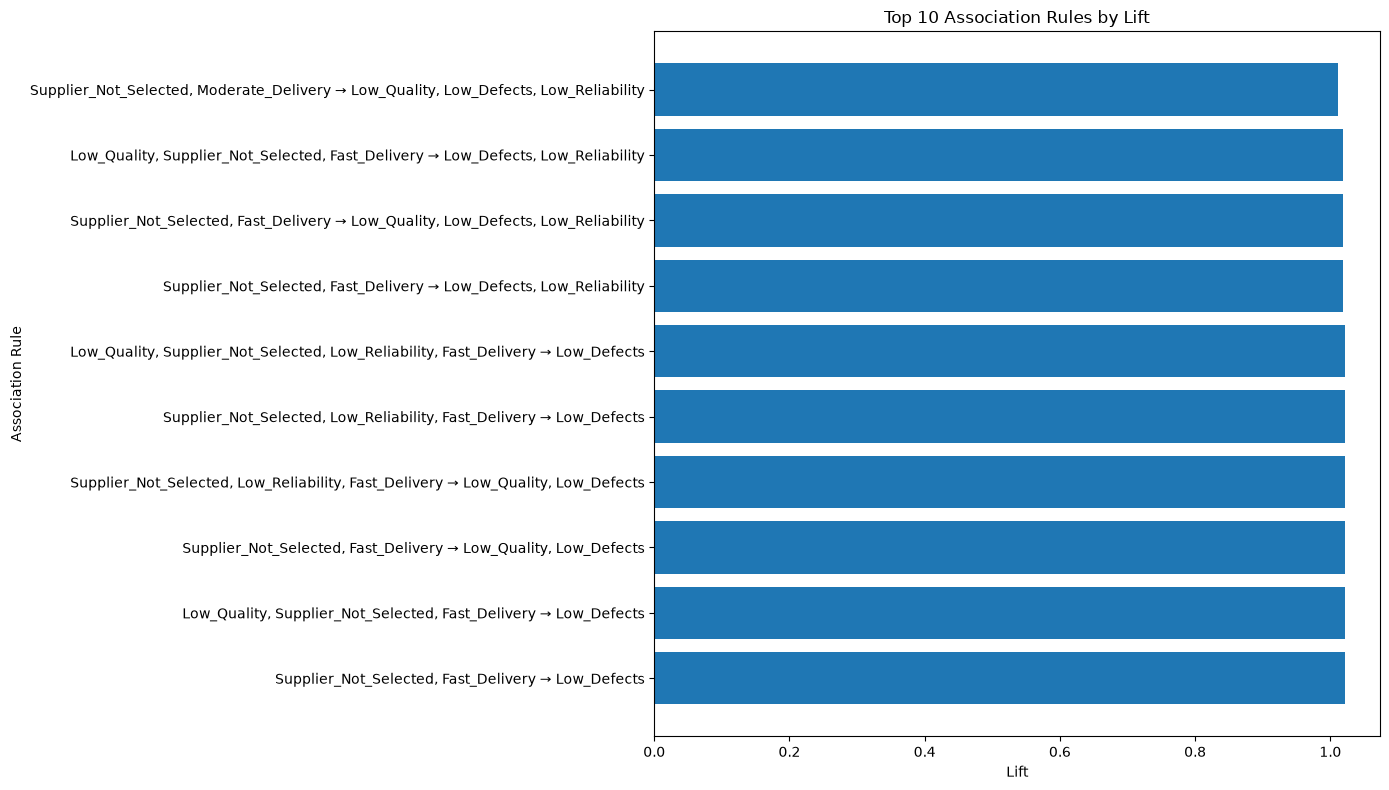

In [8]:
top10 = top_rules.head(10).copy()

top10["rule"] = top10.apply(
    lambda x: f"{', '.join(list(x['antecedents']))} → {', '.join(list(x['consequents']))}",
    axis=1
)

plt.figure(figsize=(14, 8))

plt.barh(
    top10["rule"],
    top10["lift"]
)

plt.xlabel("Lift")
plt.ylabel("Association Rule")
plt.title("Top 10 Association Rules by Lift")

plt.tight_layout()
plt.show()

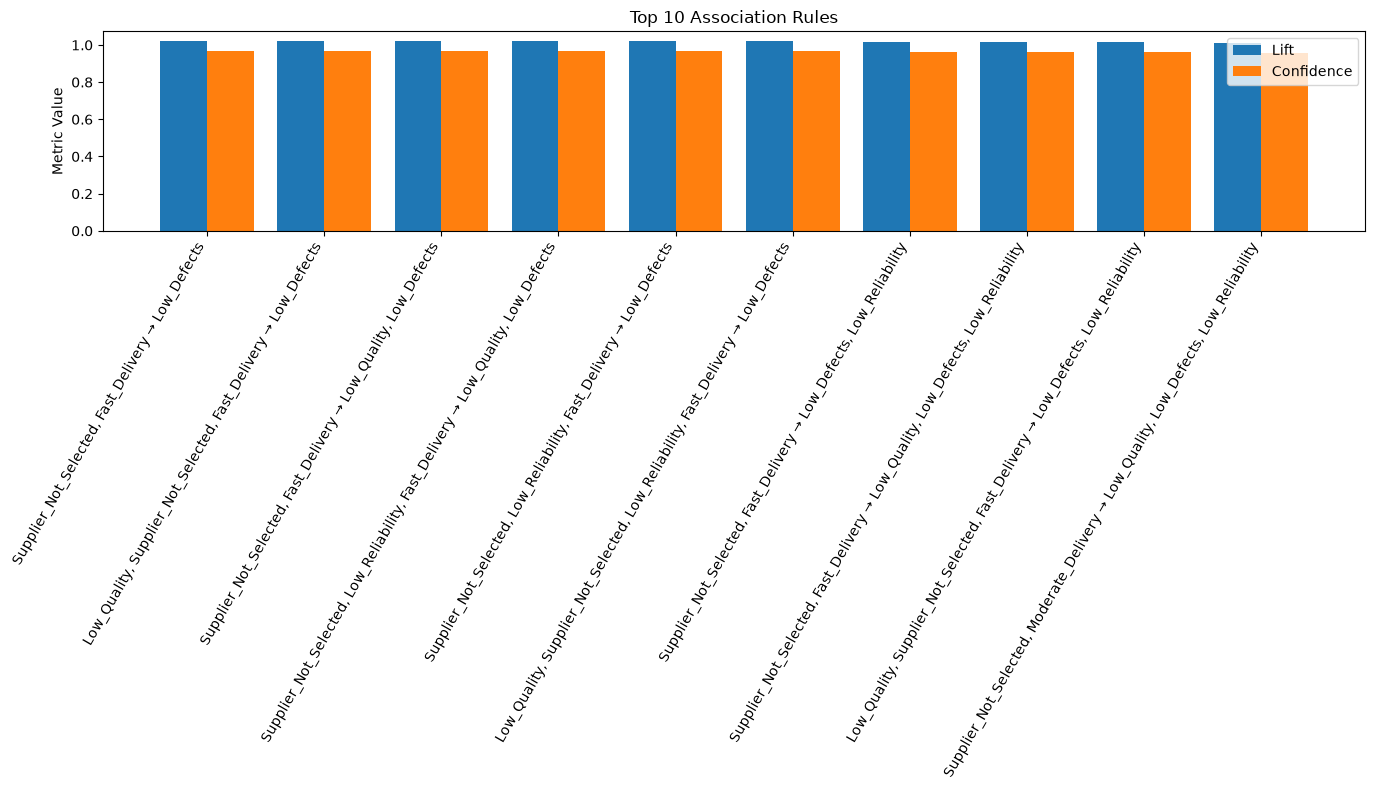

In [9]:
top10 = top_rules.head(10).copy()

top10["rule"] = top10.apply(
    lambda x: f"{', '.join(list(x['antecedents']))} → {', '.join(list(x['consequents']))}",
    axis=1
)

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(top10))
width = 0.4

ax.bar(
    x - width/2,
    top10["lift"],
    width,
    label="Lift"
)

ax.bar(
    x + width/2,
    top10["confidence"],
    width,
    label="Confidence"
)

ax.set_xticks(x)
ax.set_xticklabels(top10["rule"], rotation=60, ha="right")

ax.set_ylabel("Metric Value")
ax.set_title("Top 10 Association Rules")
ax.legend()

plt.tight_layout()
plt.show()

# Evaluation & Validation

## Rule Quality Metrics

In [10]:
rules[['support','confidence','lift']].describe()

,support,confidence,lift
count,221.000000,221.000000,221.000000
mean,0.299303,0.973809,0.999750
std,0.240222,0.026393,0.008588
min,0.079314,0.912088,0.964877
25%,0.083846,0.949285,0.997466
50%,0.174490,0.992278,1.000000
75%,0.473292,1.000000,1.003248
max,0.995792,1.000000,1.022329


## Strong Rules

In [11]:
strong_rules = rules[
    (rules['confidence'] >= 0.8)
    &
    (rules['lift'] > 1)
]

strong_rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({Fast_Delivery}),frozenset({Low_Defects}),0.170605,0.948851,0.163160,0.956357,1.007911,1.0,0.001281,1.171985,0.009463,0.170616,0.146747,0.564156
2,frozenset({Fast_Delivery}),frozenset({Low_Reliability}),0.170605,0.995792,0.169958,0.996205,1.000415,1.0,0.000071,1.108935,0.000500,0.170565,0.098234,0.583441
5,frozenset({Low_Defects}),frozenset({Low_Reliability}),0.948851,0.995792,0.945290,0.996247,1.000457,1.0,0.000432,1.121369,0.008939,0.945902,0.108233,0.972766
6,frozenset({Low_Reliability}),frozenset({Low_Defects}),0.995792,0.948851,0.945290,0.949285,1.000457,1.0,0.000432,1.008558,0.108641,0.945902,0.008485,0.972766
8,frozenset({Slow_Delivery}),frozenset({Low_Defects}),0.653610,0.948851,0.620589,0.949480,1.000663,1.0,0.000411,1.012454,0.001913,0.632047,0.012301,0.801761
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
213,"frozenset({Supplier_Not_Selected, Slow_Delivery})","frozenset({Low_Quality, Low_Defects, Low_Relia...",0.321140,0.945290,0.304306,0.947581,1.002423,1.0,0.000736,1.043703,0.003561,0.316285,0.041873,0.634749
214,"frozenset({Supplier_Selected, Low_Defects, Slo...",frozenset({Low_Reliability}),0.314665,0.995792,0.314341,0.998971,1.003193,1.0,0.001001,4.090644,0.004644,0.315567,0.755540,0.657320
217,"frozenset({Supplier_Selected, Slow_Delivery, L...","frozenset({Low_Defects, Low_Reliability})",0.332470,0.945290,0.314341,0.945472,1.000193,1.0,0.000061,1.003347,0.000289,0.326277,0.003336,0.639003
218,"frozenset({Supplier_Selected, Low_Defects, Slo...","frozenset({Low_Quality, Low_Reliability})",0.314665,0.995792,0.314341,0.998971,1.003193,1.0,0.001001,4.090644,0.004644,0.315567,0.755540,0.657320


## Business Insights

In [12]:
for _, row in strong_rules.head(10).iterrows():

    print(
        f"{set(row['antecedents'])}"
        f" -> "
        f"{set(row['consequents'])}"
    )

    print(
        f"Support: {row['support']:.3f}"
    )

    print(
        f"Confidence: {row['confidence']:.3f}"
    )

    print(
        f"Lift: {row['lift']:.3f}"
    )

    print("-"*60)

{'Fast_Delivery'} -> {'Low_Defects'}
Support: 0.163
Confidence: 0.956
Lift: 1.008
------------------------------------------------------------
{'Fast_Delivery'} -> {'Low_Reliability'}
Support: 0.170
Confidence: 0.996
Lift: 1.000
------------------------------------------------------------
{'Low_Defects'} -> {'Low_Reliability'}
Support: 0.945
Confidence: 0.996
Lift: 1.000
------------------------------------------------------------
{'Low_Reliability'} -> {'Low_Defects'}
Support: 0.945
Confidence: 0.949
Lift: 1.000
------------------------------------------------------------
{'Slow_Delivery'} -> {'Low_Defects'}
Support: 0.621
Confidence: 0.949
Lift: 1.001
------------------------------------------------------------
{'Supplier_Not_Selected'} -> {'Low_Defects'}
Support: 0.473
Confidence: 0.956
Lift: 1.008
------------------------------------------------------------
{'Slow_Delivery'} -> {'Low_Reliability'}
Support: 0.651
Confidence: 0.997
Lift: 1.001
----------------------------------------